# Tier 1: Tabular Q-learning vs DQN on CartPole-v1

1. **Tabular Q-learning** with a discretized state.
2. **DQN** with experience replay and a target network.

### Requirement checklist (Tier 1 + experimental protocol)

| Requirement | Where |
| --- | --- |
| Pertinence: why tabular / DQN fit CartPole (with numbers) | §1 |
| Tabular Q-learning with ≥ 3 discretizations (6, 10, 20 bins) + bin-range study | §3, §6.1, §6.2 |
| DQN with replay buffer, target network, ε-greedy with decay | §4 |
| Same step budget (200k), x-axis = environment steps | §0 config, §6 |
| 5 seeds, mean curve ± sd band | §6 |
| Separate greedy evaluation (10 episodes every 5k steps) and training returns | §2, §6 |
| Final return (100 ep.), steps to threshold, variance, wall-clock time, hardware | §6.5 |
| DQN stability (per-seed curves, loss, Q-values) | §6.4 |
| GIF of the trained agents | §7 |
| Reproducibility: seeds, configs, `requirements.txt` | §8 |
| Discussion: which learned faster and why, sensitivity to bins, limitations | §9 |


## 0. Setup

In [2]:
import copy
import json
import os
import platform
import random
import time
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image as ShowImage, Markdown, display
from PIL import Image

torch.set_num_threads(1)   # the network is small: 1 thread is faster


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


HARDWARE = f"{platform.processor() or platform.machine()}, {os.cpu_count()} CPUs, {platform.system()}"
print("python", platform.python_version(), "| torch", torch.__version__,
      "| gymnasium", gym.__version__, "| numpy", np.__version__)
print("hardware:", HARDWARE)

python 3.11.9 | torch 2.10.0+cpu | gymnasium 1.2.2 | numpy 2.2.6
hardware: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel, 32 CPUs, Windows


### Configuration

| | Value |
| --- | --- |
| Step budget | 200,000 steps (same for both methods) |
| Seeds | 5 |
| Evaluation | 10 greedy episodes every 5,000 steps |
| γ | 0.99 |
| Tabular | α = 0.1, ε 1.0 → 0.01 in 100k steps |
| DQN | lr 1e-3, buffer 50k, batch 64, warmup 1000, target update every 500, ε 1.0 → 0.05 in 10k steps |

**Fairness notes.** Both methods get the same step budget, the same seeds, the same evaluation episodes and the same γ.
The ε schedules differ on purpose: a Q-table only learns about a cell when it visits it, so it needs long exploration (100k steps);
the network generalizes between nearby states, so 10k steps of exploration are enough. Each schedule is the documented default of its method.


In [3]:
ENV_ID = "CartPole-v1"
SUCCESS_THRESHOLD = 475   # solved: mean return >= 475 over 100 episodes
GAMMA = 0.99

STEP_BUDGET = 200_000
SEEDS = [0, 1, 2, 3, 4]
EVAL_EVERY = 5_000
EVAL_EPISODES = 10     # episodes in each evaluation during training
FINAL_EPISODES = 100   # episodes in the final evaluation

RESULTS_DIR = Path("results/tier1")
LOG_DIR = RESULTS_DIR / "logs"       # metrics of each run (JSON)
MODEL_DIR = RESULTS_DIR / "models"   # Q-tables and network weights
FIG_DIR = RESULTS_DIR / "figures"    # plots and GIFs
for folder in [LOG_DIR, MODEL_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"steps per run: {STEP_BUDGET:,} | seeds: {SEEDS} | evaluate every {EVAL_EVERY:,} steps")

steps per run: 200,000 | seeds: [0, 1, 2, 3, 4] | evaluate every 5,000 steps


## 1. Pertinence

| Element | CartPole-v1 |
| --- | --- |
| State | 4 continuous: cart position, cart velocity, pole angle, pole angular velocity |
| Actions | 2 discrete: left (0), right (1) |
| Reward | +1 per step the pole stays up |
| End | `terminated`: pole beyond ±12° or cart beyond ±2.4. `truncated`: 500 steps |

- **DQN**: works, because the actions are discrete.
- **Tabular**: works only after **discretizing** the 4 state dimensions ($n^4$ states).

| Bins per dimension $n$ | Q-table rows $n^4$ | Q-values ($\times$ 2 actions) |
| --- | --- | --- |
| 6 | 1,296 | 2,592 |
| 10 | 10,000 | 20,000 |
| 20 | 160,000 | 320,000 |

With 200k steps, the 20-bin table has fewer than 2 samples per Q-value on average (and most steps fall in a few central cells), so
finer bins trade **resolution** for **data per cell**. The DQN network (4 → 128 → 128 → 2) has 17,410 parameters, but they are shared
across all states, so every update also changes the values of nearby, unvisited states.


In [4]:
env = gym.make(ENV_ID)
print("observation space:", env.observation_space)
print("action space     :", env.action_space)

states = []
state, _ = env.reset(seed=0)
env.action_space.seed(0)
for _ in range(20_000):
    state, reward, terminated, truncated, _ = env.step(env.action_space.sample())
    states.append(state)
    if terminated or truncated:
        state, _ = env.reset()
env.close()

states = np.array(states)
names = ["cart pos", "cart vel", "pole angle", "pole ang. vel"]
for i in range(4):
    col = states[:, i]
    print(f"{names[i]:14s} min={col.min():+.3f}  p1={np.percentile(col, 1):+.3f}  "
          f"median={np.median(col):+.3f}  p99={np.percentile(col, 99):+.3f}  max={col.max():+.3f}")

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space     : Discrete(2)
cart pos       min=-0.832  p1=-0.254  median=-0.002  p99=+0.233  max=+1.201
cart vel       min=-2.345  p1=-1.360  median=-0.008  p99=+1.354  max=+2.485
pole angle     min=-0.256  p1=-0.224  median=+0.002  p99=+0.223  max=+0.262
pole ang. vel  min=-3.035  p1=-1.998  median=+0.018  p99=+1.978  max=+3.163


These values (random policy) guide the bin ranges we test in 3.1.

## 2. Evaluation and logging

- `epsilon_by_step`: linear decay of ε, then fixed.
- `evaluate`: mean return of the **greedy** policy (ε = 0) in a separate environment.
- Training time does **not** include evaluation time.

In [5]:
def epsilon_by_step(i, eps_start, eps_end, eps_decay):
    fraction = min(1.0, i / eps_decay)
    return eps_start + fraction * (eps_end - eps_start)


EVAL_SEED = 100_000    # evaluation seeds: different from the training seeds
FINAL_SEED = 200_000   # seeds of the final 100-episode evaluation


def evaluate(policy, num_episodes, first_seed):
    # policy: function that takes a state and returns an action
    env = gym.make(ENV_ID)
    returns = []
    for k in range(num_episodes):
        state, _ = env.reset(seed=first_seed + k)
        done = False
        total_reward = 0.0
        while not done:
            state, reward, terminated, truncated, _ = env.step(policy(state))
            total_reward += reward
            done = terminated or truncated
        returns.append(total_reward)
    env.close()
    return float(np.mean(returns))


def new_log(method, seed, config):
    return {
        "method": method, "seed": seed, "config": config, "hardware": HARDWARE,
        "eval_steps": [],          # step of each evaluation
        "eval_returns": [],        # greedy return of that evaluation
        "eval_time": [],           # training seconds until that evaluation
        "episode_end_steps": [],   # step where each training episode ended
        "episode_returns": [],     # return of each training episode
    }


def add_eval(log, step, policy, train_seconds):
    log["eval_steps"].append(step)
    log["eval_returns"].append(evaluate(policy, EVAL_EPISODES, EVAL_SEED))
    log["eval_time"].append(train_seconds)


def steps_to_threshold(log):
    # First step where the evaluation reached the threshold, or None if it never did
    for step, ret in zip(log["eval_steps"], log["eval_returns"]):
        if ret >= SUCCESS_THRESHOLD:
            return step
    return None

## 3. Tabular Q-learning

### 3.1 Discretizer

Each dimension is split into `n_bins` equal bins between `low` and `high` (values outside are clipped). The 4 bins are combined into one index: $s = b_0 + n\,b_1 + n^2 b_2 + n^3 b_3$.

| Range | cart pos | cart vel | pole angle | pole ang. vel |
| --- | --- | --- | --- | --- |
| `narrow` | ±2.4 | ±1.0 | ±0.21 | ±1.0 |
| `default` | ±2.4 | ±3.0 | ±0.21 | ±3.5 |
| `wide` | ±4.8 | ±5.0 | ±0.42 | ±5.0 |

In [6]:
#            low (minimum)                 high (maximum)
RANGES = {
    "narrow":  ([-2.4, -1.0, -0.21, -1.0], [2.4, 1.0, 0.21, 1.0]),
    "default": ([-2.4, -3.0, -0.21, -3.5], [2.4, 3.0, 0.21, 3.5]),
    "wide":    ([-4.8, -5.0, -0.42, -5.0], [4.8, 5.0, 0.42, 5.0]),
}


class Discretizer:
    def __init__(self, n_bins, low, high):
        self.n_bins = n_bins
        self.low = np.array(low)
        self.width = (np.array(high) - self.low) / n_bins   # width of one bin in each dimension
        self.num_states = n_bins ** 4                       # rows of the Q-table
        self.powers = n_bins ** np.arange(4)                # [1, n, n^2, n^3]

    def __call__(self, state):
        bins = np.floor((state - self.low) / self.width).astype(int)   # bin of each dimension
        bins = np.clip(bins, 0, self.n_bins - 1)                      # clip values outside the range
        return int(np.dot(bins, self.powers))                         # combine the 4 bins into one index


d = Discretizer(10, *RANGES["default"])
print("states in the table:", d.num_states)
print("state (0, 0, 0, 0)     ->", d(np.zeros(4)))
print("minimum corner         ->", d(np.array(RANGES["default"][0])))
print("out of range (clipped) ->", d(np.array([99.0, 99.0, 99.0, 99.0])))

states in the table: 10000
state (0, 0, 0, 0)     -> 5555
minimum corner         -> 0
out of range (clipped) -> 9999


### 3.2 Q-learning

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

The target is only $r$ when `terminated` (pole fell). At `truncated` (500 steps) the state is not terminal, so we still bootstrap.

In [7]:
def epsilon_greedy_policy(Q, epsilon, state, num_actions):
    if random.random() < epsilon:
        return random.randrange(num_actions)
    return int(np.argmax(Q[state]))


def q_learning_control(name, seed, n_bins, ranges="default", num_steps=STEP_BUDGET,
                       gamma=GAMMA, alpha=0.1, eps_start=1.0, eps_end=0.01, eps_decay=STEP_BUDGET // 2):
    config = {"n_bins": n_bins, "ranges": ranges, "num_steps": num_steps, "gamma": gamma, "alpha": alpha,
              "eps_start": eps_start, "eps_end": eps_end, "eps_decay": eps_decay}
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    disc = Discretizer(n_bins, *RANGES[ranges])
    num_actions = env.action_space.n
    Q = np.zeros((disc.num_states, num_actions))
    visits = np.zeros(disc.num_states, dtype=int)

    def greedy_policy(state):
        return int(np.argmax(Q[disc(state)]))

    log = new_log("tabular", seed, config)
    start = time.perf_counter()
    eval_seconds = 0.0
    add_eval(log, 0, greedy_policy, 0.0)
    eval_seconds += time.perf_counter() - start

    state, _ = env.reset(seed=seed)
    s = disc(state)
    episode_return = 0.0
    i = 0
    while i < num_steps:
        epsilon = epsilon_by_step(i, eps_start, eps_end, eps_decay)
        action = epsilon_greedy_policy(Q, epsilon, s, num_actions)
        next_state, reward, terminated, truncated, _ = env.step(action)
        i += 1
        s_next = disc(next_state)

        # off-policy target: bootstrap from the best value at s' (only if the pole did not fall)
        if terminated:
            target = reward
        else:
            target = reward + gamma * np.max(Q[s_next])
        Q[s, action] += alpha * (target - Q[s, action])

        visits[s] += 1
        episode_return += reward
        s = s_next
        if terminated or truncated:
            log["episode_end_steps"].append(i)
            log["episode_returns"].append(episode_return)
            state, _ = env.reset()
            s = disc(state)
            episode_return = 0.0

        if i % EVAL_EVERY == 0:
            t0 = time.perf_counter()
            add_eval(log, i, greedy_policy, t0 - start - eval_seconds)
            eval_seconds += time.perf_counter() - t0
    env.close()

    log["train_time"] = time.perf_counter() - start - eval_seconds
    log["final_return"] = evaluate(greedy_policy, FINAL_EPISODES, FINAL_SEED)
    log["states_visited"] = int(np.sum(visits > 0))
    log["num_states"] = disc.num_states
    np.savez_compressed(MODEL_DIR / f"{name}.npz", Q=Q, n_bins=n_bins, ranges=ranges)
    return log

## 4. DQN

- **`QNetwork`**: MLP 4 → 128 → 128 → 2 (one Q-value per action).
- **`ReplayBuffer`**: circular memory; random mini-batches break the correlation between steps.
- **Target network** θ⁻: copy of the network, updated every C = 500 steps.
- **Loss**: MSE between $Q(s,a;\theta)$ and $y = r + \gamma\,(1 - terminated)\,\max_{a'} Q(s',a';\theta^-)$.
- For the stability analysis (§6.4) we also log the mean loss and the mean $\max_a Q(s,a)$ of the sampled batches between two evaluations.


In [8]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)          # shape: (batch, n_actions)


class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.N = capacity
        self.c = 0                                   # transitions ever added
        self.s    = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a    = np.zeros(capacity, dtype=np.int64)
        self.r    = np.zeros(capacity, dtype=np.float32)
        self.s2   = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        i = self.c % self.N                          # position to write
        self.s[i] = s
        self.a[i] = a
        self.r[i] = r
        self.s2[i] = s2
        self.done[i] = done
        self.c += 1

    def __len__(self):
        return min(self.c, self.N)

    def sample(self, n):
        idx = np.random.randint(0, len(self), size=n)   # n random indices
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.done[idx]


def select_action(q_net, s, eps, n_actions):
    # `eps > 0` first: a greedy evaluation (eps = 0) must not consume random numbers,
    # otherwise evaluating would change the training run.
    if eps > 0 and random.random() < eps:
        return random.randrange(n_actions)
    with torch.no_grad():
        q_values = q_net(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))
    return int(q_values.argmax(dim=1).item())


def compute_loss(q_net, target_net, batch, gamma):
    s, a, r, s2, done = (torch.as_tensor(x) for x in batch)
    q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)          # Q(s, a; θ) of the action taken
    with torch.no_grad():
        max_next = target_net(s2).max(dim=1).values                # max_a' Q(s', a'; θ⁻)
        target = r + gamma * (1 - done) * max_next
    return ((q_sa - target) ** 2).mean()                          # MSE

### 4.1 Training loop

1. ε-greedy action → store the transition in the buffer.
2. After `warmup`: sample a mini-batch, compute the loss, one Adam step.
3. Every `C` steps: copy the weights to the target network.

In [9]:
def train_dqn(name, seed, num_steps=STEP_BUDGET, capacity=50_000, batch=64, warmup=1_000, C=500,
              gamma=GAMMA, lr=1e-3, eps_start=1.0, eps_end=0.05, eps_decay=10_000):
    config = {"num_steps": num_steps, "capacity": capacity, "batch": batch, "warmup": warmup, "C": C,
              "gamma": gamma, "lr": lr, "eps_start": eps_start, "eps_end": eps_end, "eps_decay": eps_decay}
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    state_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n

    q_net = QNetwork(state_dim, n_actions)
    target_net = copy.deepcopy(q_net)                      # θ⁻ ← θ
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    buf = ReplayBuffer(capacity, state_dim)

    def greedy_policy(state):
        return select_action(q_net, state, 0.0, n_actions)

    log = new_log("dqn", seed, config)
    start = time.perf_counter()
    eval_seconds = 0.0
    add_eval(log, 0, greedy_policy, 0.0)
    eval_seconds += time.perf_counter() - start

    log["loss"] = []     # mean TD loss since the previous evaluation
    log["q_mean"] = []   # mean max_a Q(s, a) of the sampled batches since the previous evaluation
    loss_sum, q_sum, n_updates = 0.0, 0.0, 0

    s, _ = env.reset(seed=seed)
    episode_return = 0.0
    for i in range(1, num_steps + 1):
        # 1) act and store the transition
        eps = epsilon_by_step(i, eps_start, eps_end, eps_decay)
        a = select_action(q_net, s, eps, n_actions)
        s2, r, terminated, truncated, _ = env.step(a)
        buf.add(s, a, r, s2, float(terminated))
        s = s2
        episode_return += r
        if terminated or truncated:
            log["episode_end_steps"].append(i)
            log["episode_returns"].append(episode_return)
            s, _ = env.reset()
            episode_return = 0.0

        # 2) learn from a mini-batch
        if len(buf) > warmup and len(buf) > batch:
            sample = buf.sample(batch)
            loss = compute_loss(q_net, target_net, sample, gamma)
            opt.zero_grad()
            loss.backward()
            opt.step()
            with torch.no_grad():
                q_sum += q_net(torch.as_tensor(sample[0])).max(dim=1).values.mean().item()
            loss_sum += loss.item()
            n_updates += 1

        # 3) update the target network
        if i % C == 0:
            target_net.load_state_dict(q_net.state_dict())

        if i % EVAL_EVERY == 0:
            t0 = time.perf_counter()
            add_eval(log, i, greedy_policy, t0 - start - eval_seconds)
            log["loss"].append(loss_sum / max(n_updates, 1))
            log["q_mean"].append(q_sum / max(n_updates, 1))
            loss_sum, q_sum, n_updates = 0.0, 0.0, 0
            eval_seconds += time.perf_counter() - t0
    env.close()

    log["train_time"] = time.perf_counter() - start - eval_seconds
    log["final_return"] = evaluate(greedy_policy, FINAL_EPISODES, FINAL_SEED)
    torch.save(q_net.state_dict(), MODEL_DIR / f"{name}.pt")
    return log

## 5. Experiments

| Group | Runs (× 5 seeds) |
| --- | --- |
| Number of bins | tabular with 6, 10, 20 bins (`default` range) |
| Bin ranges | tabular with 10 bins, `narrow` and `wide` |
| DQN | DQN |

Each run saves its log in `results/tier1/logs/`. Runs that are already saved are loaded, not trained again.

In [10]:
def run_job(name, method, params):
    if method == "tabular":
        log = q_learning_control(name, **params)
    else:
        log = train_dqn(name, **params)
    with open(LOG_DIR / f"{name}.json", "w") as f:
        json.dump(log, f)
    print(f"done {name:24s} final return = {log['final_return']:6.1f}   time = {log['train_time']:6.1f} s", flush=True)


def run_all(jobs):
    pending = [job for job in jobs if not (LOG_DIR / f"{job[0]}.json").exists()]
    print(f"{len(jobs) - len(pending)} runs already saved, {len(pending)} to train")
    for job in pending:
        run_job(*job)

    logs = {}
    for name, _, _ in jobs:
        with open(LOG_DIR / f"{name}.json") as f:
            logs[name] = json.load(f)
    return logs


BIN_COUNTS = [6, 10, 20]

jobs = []
for seed in SEEDS:
    jobs.append((f"dqn_s{seed}", "dqn", {"seed": seed}))
    for b in BIN_COUNTS:
        jobs.append((f"tab_b{b}_default_s{seed}", "tabular", {"seed": seed, "n_bins": b, "ranges": "default"}))
    for r in ["narrow", "wide"]:
        jobs.append((f"tab_b10_{r}_s{seed}", "tabular", {"seed": seed, "n_bins": 10, "ranges": r}))

t0 = time.perf_counter()
LOGS = run_all(jobs)
print(f"total time: {time.perf_counter() - t0:.0f} s")

0 runs already saved, 30 to train
done dqn_s0                   final return =  484.9   time =  722.5 s
done tab_b6_default_s0        final return =  179.6   time =    5.2 s
done tab_b10_default_s0       final return =  262.5   time =    5.1 s
done tab_b20_default_s0       final return =  170.2   time =    4.7 s
done tab_b10_narrow_s0        final return =  393.9   time =    6.3 s
done tab_b10_wide_s0          final return =  398.3   time =   12.0 s
done dqn_s1                   final return =  354.2   time =  474.2 s
done tab_b6_default_s1        final return =  227.2   time =    4.7 s
done tab_b10_default_s1       final return =  108.0   time =    4.8 s
done tab_b20_default_s1       final return =  216.9   time =    4.7 s
done tab_b10_narrow_s1        final return =  173.2   time =    4.6 s
done tab_b10_wide_s1          final return =  166.3   time =    4.6 s
done dqn_s2                   final return =  452.5   time =  369.2 s
done tab_b6_default_s2        final return =  281.6   ti

## 6. Results

Mean over the 5 seeds (line) ± one standard deviation (band).
- **Evaluation curve:** greedy return.
- **Training curve:** moving average of 20 training episodes, interpolated on a common step grid.

In [11]:
def get_group(prefix):
    # Logs of all seeds of one experiment, e.g. get_group("dqn")
    return [LOGS[f"{prefix}_s{seed}"] for seed in SEEDS]


GROUPS = {
    "Tabular 6 bins": get_group("tab_b6_default"),
    "Tabular 10 bins": get_group("tab_b10_default"),
    "Tabular 20 bins": get_group("tab_b20_default"),
    "Tabular 10 bins, narrow": get_group("tab_b10_narrow"),
    "Tabular 10 bins, wide": get_group("tab_b10_wide"),
    "DQN": get_group("dqn"),
}


def eval_curve(logs):
    x = np.array(logs[0]["eval_steps"])
    Y = np.array([log["eval_returns"] for log in logs])   # one row per seed
    return x, Y


def train_curve(logs, window=20):
    x = np.linspace(0, STEP_BUDGET, 200)
    Y = []
    for log in logs:
        rets = np.array(log["episode_returns"])
        smooth = np.convolve(rets, np.ones(window) / window, mode="valid")
        steps = np.array(log["episode_end_steps"])[window - 1:]
        Y.append(np.interp(x, steps, smooth))
    return x, np.array(Y)


def plot_mean_std(ax, x, Y, label):
    mean = Y.mean(axis=0)
    std = Y.std(axis=0)
    line = ax.plot(x, mean, label=label)[0]
    ax.fill_between(x, mean - std, mean + std, color=line.get_color(), alpha=0.2)


def plot_groups(names, title, filename, kind="eval"):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for name in names:
        if kind == "eval":
            x, Y = eval_curve(GROUPS[name])
        else:
            x, Y = train_curve(GROUPS[name])
        plot_mean_std(ax, x, Y, name)
    ax.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1, label=f"threshold {SUCCESS_THRESHOLD}")
    ax.set_xlabel("environment steps")
    if kind == "eval":
        ax.set_ylabel("evaluation return (greedy)")
    else:
        ax.set_ylabel("training return (moving avg. 20)")
    ax.set_title(f"{title} — {len(SEEDS)} seeds, mean ± sd")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

### 6.1 Tabular: number of bins

We also print the % of the table that was visited.

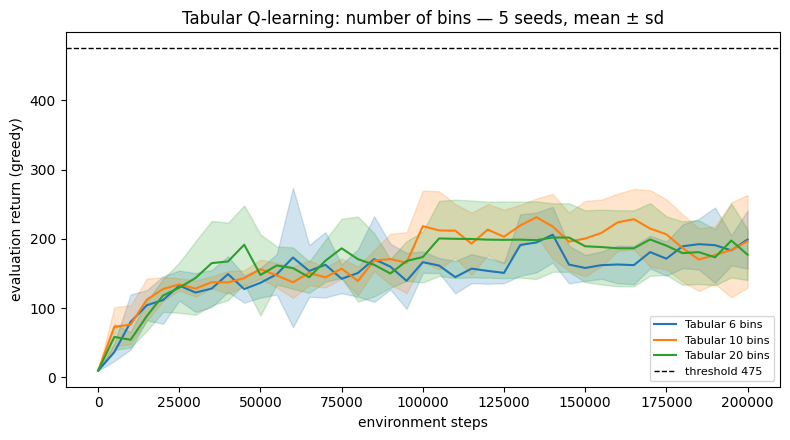

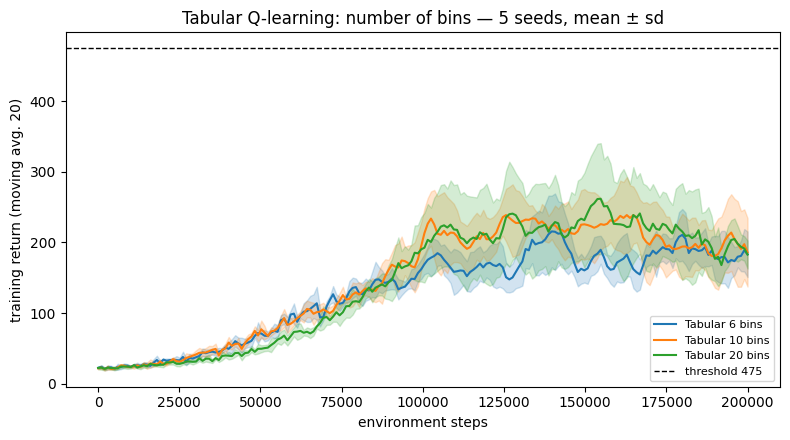

Tabular 6 bins  :   1,296 states, visited on average      354 (27.3%)
Tabular 10 bins :  10,000 states, visited on average      858 (8.6%)
Tabular 20 bins : 160,000 states, visited on average    2,678 (1.7%)


In [12]:
BIN_NAMES = ["Tabular 6 bins", "Tabular 10 bins", "Tabular 20 bins"]
plot_groups(BIN_NAMES, "Tabular Q-learning: number of bins", "tab_bins_eval.png")
plot_groups(BIN_NAMES, "Tabular Q-learning: number of bins", "tab_bins_train.png", kind="train")

for name in BIN_NAMES:
    logs = GROUPS[name]
    visited = np.mean([log["states_visited"] for log in logs])
    total = logs[0]["num_states"]
    print(f"{name:16s}: {total:7,d} states, visited on average {visited:8,.0f} ({visited / total:.1%})")

### 6.2 Tabular: bin ranges (10 bins)

`default` is the same 10-bin run from 6.1.

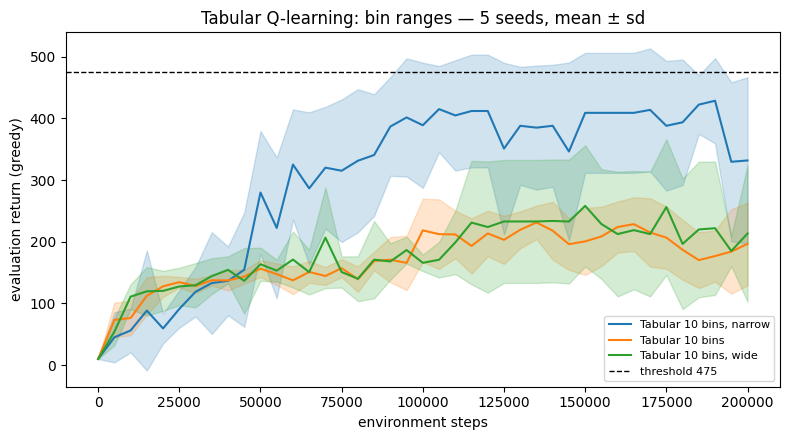

In [13]:
RANGE_NAMES = ["Tabular 10 bins, narrow", "Tabular 10 bins", "Tabular 10 bins, wide"]
plot_groups(RANGE_NAMES, "Tabular Q-learning: bin ranges", "tab_ranges_eval.png")

### 6.3 Tabular vs DQN

Same step budget, seeds and evaluation. The last plot uses training time (log scale) on the X axis.

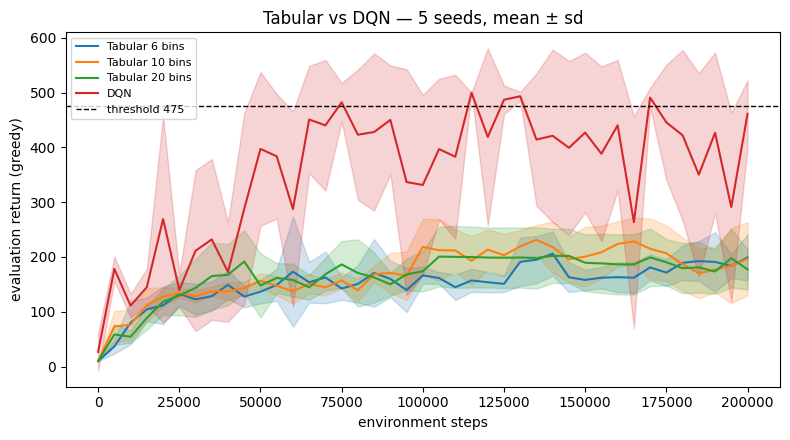

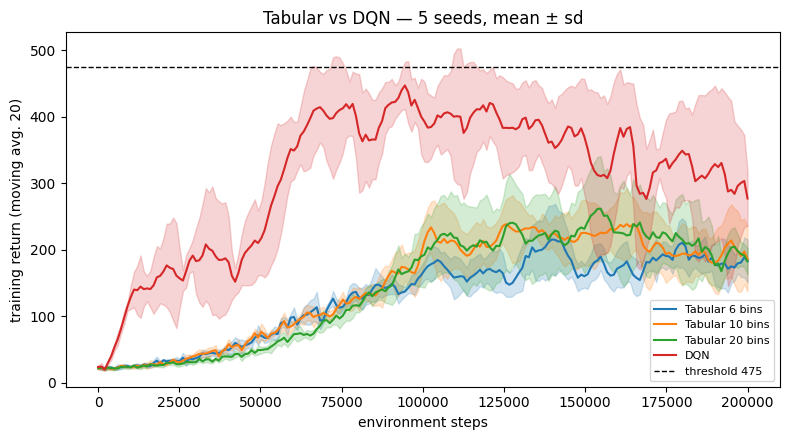

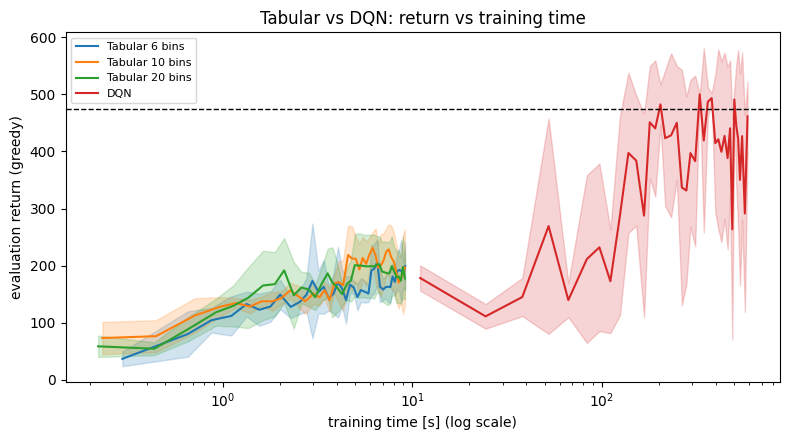

In [14]:
COMPARE = ["Tabular 6 bins", "Tabular 10 bins", "Tabular 20 bins", "DQN"]
plot_groups(COMPARE, "Tabular vs DQN", "tab_vs_dqn_eval.png")
plot_groups(COMPARE, "Tabular vs DQN", "tab_vs_dqn_train.png", kind="train")

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in COMPARE:
    logs = GROUPS[name]
    x = np.mean([log["eval_time"] for log in logs], axis=0)
    Y = eval_curve(logs)[1]
    plot_mean_std(ax, x[1:], Y[:, 1:], name)   # skip point 0 (time 0 does not exist on a log scale)
ax.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("training time [s] (log scale)")
ax.set_ylabel("evaluation return (greedy)")
ax.set_title("Tabular vs DQN: return vs training time")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "tab_vs_dqn_walltime.png", dpi=150)
plt.show()

### 6.4 DQN stability

The mean ± sd band hides what happens inside each run, so here we look at the **5 DQN seeds one by one**:

- **Per-seed evaluation curves**: does a seed reach 500 and stay there, or does it collapse afterwards?
- **Loss and mean $\max_a Q$**: with γ = 0.99 and +1 per step, the true value of a perfect policy is at most $\sum_t \gamma^t = 1/(1-\gamma) = 100$.
  Q-values far above 100 indicate overestimation (the max in the target picks noisy high values).
- **Stability metrics**: number of evaluations that fall below the threshold *after* the seed first reached it, and the drop from the best evaluation to the last one.


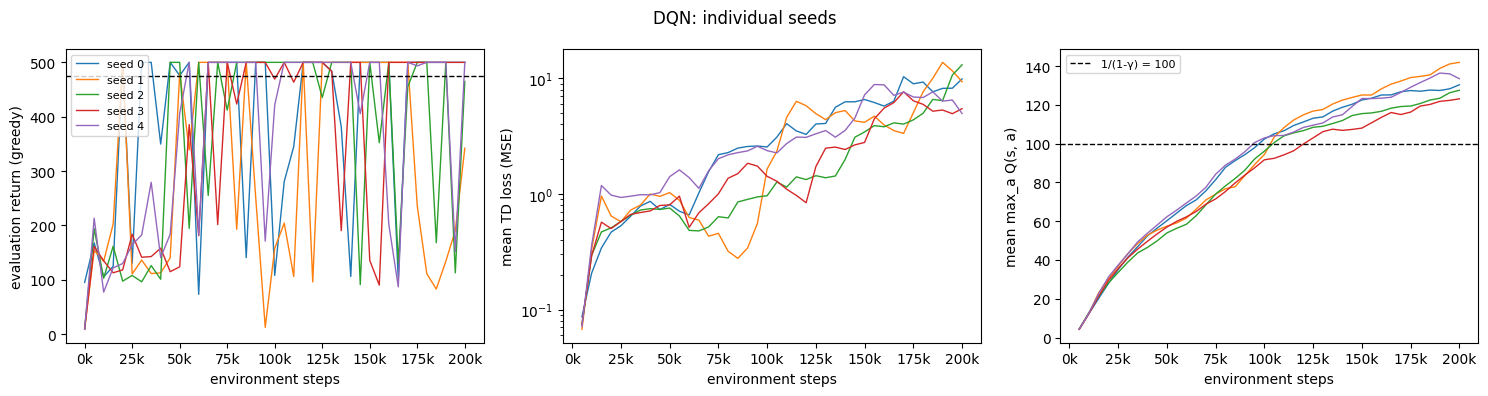

seed | first ≥ 475 | evals < 475 after that | best eval | last eval | final 100 ep.
   0 |      20,000 |                  10/37 |     500.0 |     500.0 | 484.9
   1 |      20,000 |                  19/37 |     500.0 |     342.1 | 354.2
   2 |      45,000 |                  11/32 |     500.0 |     464.9 | 452.5
   3 |      65,000 |                   7/28 |     500.0 |     500.0 | 500.0
   4 |      55,000 |                   7/30 |     500.0 |     500.0 | 500.0


In [15]:
dqn_logs = GROUPS["DQN"]
x = np.array(dqn_logs[0]["eval_steps"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for log in dqn_logs:
    axes[0].plot(x, log["eval_returns"], label=f"seed {log['seed']}", linewidth=1)
    axes[1].plot(x[1:], log["loss"], linewidth=1)
    axes[2].plot(x[1:], log["q_mean"], linewidth=1)
axes[0].axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
axes[0].set_ylabel("evaluation return (greedy)")
axes[0].legend(fontsize=8)
axes[1].set_ylabel("mean TD loss (MSE)")
axes[1].set_yscale("log")
axes[2].axhline(1 / (1 - GAMMA), color="black", linestyle="--", linewidth=1, label="1/(1-γ) = 100")
axes[2].set_ylabel("mean max_a Q(s, a)")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("environment steps")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
fig.suptitle("DQN: individual seeds")
fig.tight_layout()
fig.savefig(FIG_DIR / "dqn_stability.png", dpi=150)
plt.show()


def stability(log):
    rets = np.array(log["eval_returns"])
    first = steps_to_threshold(log)
    if first is None:
        drops = None
    else:
        k = log["eval_steps"].index(first)
        drops = int(np.sum(rets[k:] < SUCCESS_THRESHOLD))
    return first, drops, rets.max(), rets[-1]


print("seed | first ≥ 475 | evals < 475 after that | best eval | last eval | final 100 ep.")
for log in dqn_logs:
    first, drops, best, last = stability(log)
    first_text = f"{first:,}" if first is not None else "never"
    drops_text = f"{drops}/{len(log['eval_steps']) - log['eval_steps'].index(first)}" if first is not None else "-"
    print(f"{log['seed']:4d} | {first_text:>11s} | {drops_text:>22s} | {best:9.1f} | {last:9.1f} | {log['final_return']:.1f}")


For comparison, the same per-seed view for the best tabular configuration (variance between seeds is the other side of stability):

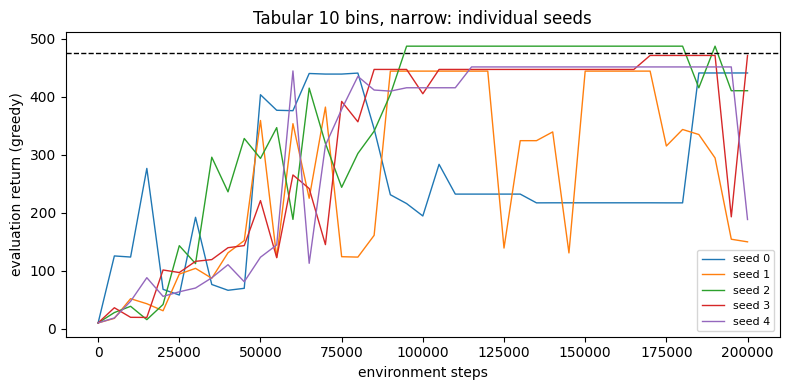

best tabular configuration: Tabular 10 bins, narrow


In [16]:
best_tab = max([n for n in GROUPS if n != "DQN"],
               key=lambda n: np.mean([log["final_return"] for log in GROUPS[n]]))
fig, ax = plt.subplots(figsize=(8, 4))
for log in GROUPS[best_tab]:
    ax.plot(log["eval_steps"], log["eval_returns"], label=f"seed {log['seed']}", linewidth=1)
ax.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("environment steps")
ax.set_ylabel("evaluation return (greedy)")
ax.set_title(f"{best_tab}: individual seeds")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "tab_best_seeds.png", dpi=150)
plt.show()
print("best tabular configuration:", best_tab)


### 6.5 Summary table

- **Final eval**: last 10-episode evaluation.
- **Final 100 ep.**: greedy return over 100 episodes; **Solved** = seeds with ≥ 475.
- **Steps to threshold**: first evaluation ≥ 475 (median over the seeds that reach it).
- **Best eval**: highest 10-episode evaluation during training.
- **Mean last 10 evals**: average of the evaluations of the last 50k steps — less dependent on *when* training stops than *Final eval*.
- **Time**: training time per run, without evaluation.
- All values: mean ± sd over the 5 seeds.

In [17]:
lines = [
    "| Method | Final eval | Best eval | Mean last 10 evals | Final 100 ep. | Solved | Steps to threshold | Reached | Time [s] |",
    "| --- | --- | --- | --- | --- | --- | --- | --- | --- |",
]
for name, logs in GROUPS.items():
    last_eval = np.array([log["eval_returns"][-1] for log in logs])
    final100 = np.array([log["final_return"] for log in logs])
    best_eval = np.array([max(log["eval_returns"]) for log in logs])
    last10 = np.array([np.mean(log["eval_returns"][-10:]) for log in logs])   # last 50k steps
    times = np.array([log["train_time"] for log in logs])
    solved = int(np.sum(final100 >= SUCCESS_THRESHOLD))

    hits = []
    for log in logs:
        step = steps_to_threshold(log)
        if step is not None:
            hits.append(step)
    if len(hits) > 0:
        hit_text = f"{int(np.median(hits)):,}"
    else:
        hit_text = "not reached"

    lines.append(f"| {name} | {last_eval.mean():.1f} ± {last_eval.std():.1f} | {best_eval.mean():.1f} ± {best_eval.std():.1f} | {last10.mean():.1f} ± {last10.std():.1f} | {final100.mean():.1f} ± {final100.std():.1f} "
                 f"| {solved}/{len(logs)} | {hit_text} | {len(hits)}/{len(logs)} | {times.mean():.1f} ± {times.std():.1f} |")

table = "\n".join(lines)
train_hardware = LOGS["dqn_s0"]["hardware"]   # machine where the runs were trained
(RESULTS_DIR / "summary.md").write_text(f"Hardware: {train_hardware}\n\n{table}\n")
display(Markdown(table))
print(table)   # plain-text copy (also saved in results/tier1/summary.md)
print("trained on:", train_hardware)

| Method | Final eval | Best eval | Mean last 10 evals | Final 100 ep. | Solved | Steps to threshold | Reached | Time [s] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Tabular 6 bins | 199.2 ± 42.0 | 262.8 ± 53.9 | 179.5 ± 8.8 | 195.8 ± 52.6 | 0/5 | not reached | 0/5 | 9.2 ± 3.5 |
| Tabular 10 bins | 196.6 ± 67.0 | 245.1 ± 36.3 | 199.7 ± 37.5 | 205.4 ± 73.4 | 0/5 | not reached | 0/5 | 9.2 ± 3.5 |
| Tabular 20 bins | 177.3 ± 36.6 | 245.8 ± 29.9 | 186.0 ± 46.3 | 192.8 ± 22.7 | 0/5 | not reached | 0/5 | 9.2 ± 3.7 |
| Tabular 10 bins, narrow | 331.9 ± 135.0 | 458.7 ± 17.6 | 393.6 ± 61.0 | 330.1 ± 100.9 | 0/5 | 95,000 | 1/5 | 8.5 ± 3.1 |
| Tabular 10 bins, wide | 213.4 ± 110.8 | 316.3 ± 82.6 | 216.5 ± 91.5 | 215.1 ± 92.5 | 0/5 | not reached | 0/5 | 9.1 ± 3.6 |
| DQN | 461.4 ± 61.2 | 500.0 ± 0.0 | 398.1 ± 57.1 | 458.3 ± 54.9 | 3/5 | 45,000 | 5/5 | 587.5 ± 153.4 |

| Method | Final eval | Best eval | Mean last 10 evals | Final 100 ep. | Solved | Steps to threshold | Reached | Time [s] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Tabular 6 bins | 199.2 ± 42.0 | 262.8 ± 53.9 | 179.5 ± 8.8 | 195.8 ± 52.6 | 0/5 | not reached | 0/5 | 9.2 ± 3.5 |
| Tabular 10 bins | 196.6 ± 67.0 | 245.1 ± 36.3 | 199.7 ± 37.5 | 205.4 ± 73.4 | 0/5 | not reached | 0/5 | 9.2 ± 3.5 |
| Tabular 20 bins | 177.3 ± 36.6 | 245.8 ± 29.9 | 186.0 ± 46.3 | 192.8 ± 22.7 | 0/5 | not reached | 0/5 | 9.2 ± 3.7 |
| Tabular 10 bins, narrow | 331.9 ± 135.0 | 458.7 ± 17.6 | 393.6 ± 61.0 | 330.1 ± 100.9 | 0/5 | 95,000 | 1/5 | 8.5 ± 3.1 |
| Tabular 10 bins, wide | 213.4 ± 110.8 | 316.3 ± 82.6 | 216.5 ± 91.5 | 215.1 ± 92.5 | 0/5 | not reached | 0/5 | 9.1 ± 3.6 |
| DQN | 461.4 ± 61.2 | 500.0 ± 0.0 | 398.1 ± 57.1 | 458.3 ± 54.9 | 3/5 | 45,000 | 5/5 | 587.5 ± 153.4 |
trained on: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel, 32 CPUs, Windows


## 7. GIF of the trained agent

One GIF per method: the run with the highest final return (tabular and DQN).

tabular: tab_b10_narrow_s3, return of the recorded episode = 500


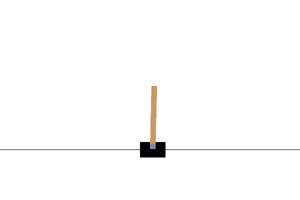

dqn: dqn_s3, return of the recorded episode = 500


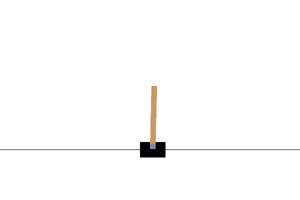

In [18]:
def load_tabular_policy(name):
    data = np.load(MODEL_DIR / f"{name}.npz")
    Q = data["Q"]
    disc = Discretizer(int(data["n_bins"]), *RANGES[str(data["ranges"])])

    def policy(state):
        return int(np.argmax(Q[disc(state)]))
    return policy


def load_dqn_policy(name):
    q_net = QNetwork(4, 2)
    q_net.load_state_dict(torch.load(MODEL_DIR / f"{name}.pt"))

    def policy(state):
        return select_action(q_net, state, 0.0, 2)
    return policy


def record_gif(policy, path):
    env = gym.make(ENV_ID, render_mode="rgb_array")
    state, _ = env.reset(seed=FINAL_SEED)
    frames = [env.render()]
    done = False
    total_reward = 0.0
    while not done:
        state, reward, terminated, truncated, _ = env.step(policy(state))
        frames.append(env.render())
        total_reward += reward
        done = terminated or truncated
    env.close()
    images = [Image.fromarray(frame).resize((300, 200)) for frame in frames[::2]]   # 1 of every 2 frames
    images[0].save(path, save_all=True, append_images=images[1:], duration=40, loop=0)
    return total_reward


for method in ["tabular", "dqn"]:
    # best run of this method (highest return over the 100 final episodes)
    runs = [name for name in LOGS if LOGS[name]["method"] == method]
    best = max(runs, key=lambda name: LOGS[name]["final_return"])
    if method == "dqn":
        policy = load_dqn_policy(best)
    else:
        policy = load_tabular_policy(best)
    path = FIG_DIR / f"{method}_best.gif"
    ret = record_gif(policy, path)
    print(f"{method}: {best}, return of the recorded episode = {ret:.0f}")
    display(ShowImage(filename=str(path)))

## 8. Reproducibility

- Seeds are fixed for Python `random`, NumPy, PyTorch, the training environment (`reset(seed)`, `action_space.seed`) and the evaluation environments (fixed evaluation seeds, different from the training seeds).
- Every log stores its full configuration and the hardware (`results/tier1/logs/*.json`); trained Q-tables and network weights are in `results/tier1/models/`.
- The cell below writes `requirements.txt` (in this folder) as a snapshot of the exact versions used for Tier 1; install from the root `../requirements.txt`. It also writes `results/tier1/configs.json` with every run.
- **One command reproduces all Tier 1 figures and tables** (delete `results/tier1/logs/` first to retrain from scratch):

```bash
pip install -r ../requirements.txt
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 tier1_cartpole_1.ipynb
```


In [19]:
import importlib.metadata as md_

packages = ["gymnasium", "pygame", "pygame-ce", "numpy", "torch", "matplotlib", "pillow", "ipython"]
reqs = []
for p in packages:
    try:
        reqs.append(f"{p}=={md_.version(p)}")
    except md_.PackageNotFoundError:
        pass   # e.g. only one of pygame / pygame-ce is installed
Path("requirements.txt").write_text("\n".join(reqs) + "\n")
print("requirements.txt:\n" + "\n".join(reqs))
print("python", platform.python_version())

configs = {name: {"method": method, **params} for name, method, params in jobs}
(RESULTS_DIR / "configs.json").write_text(json.dumps(configs, indent=1))
print(f"\n{len(configs)} run configs saved in {RESULTS_DIR / 'configs.json'}")
print("files in results/tier1/figures:", sorted(p.name for p in FIG_DIR.iterdir()))


requirements.txt:
gymnasium==1.2.2
pygame==2.6.1
numpy==2.2.6
torch==2.10.0
matplotlib==3.10.8
pillow==13.0.0
ipython==9.18.1
python 3.11.9

30 run configs saved in results\tier1\configs.json
files in results/tier1/figures: ['dqn_best.gif', 'dqn_stability.png', 'tab_best_seeds.png', 'tab_bins_eval.png', 'tab_bins_train.png', 'tab_ranges_eval.png', 'tab_vs_dqn_eval.png', 'tab_vs_dqn_train.png', 'tab_vs_dqn_walltime.png', 'tabular_best.gif']


## 9. Discussion

The cell below prints the numbers the discussion relies on, so the text can be checked against the runs.

In [20]:
def summary(name):
    logs = GROUPS[name]
    hits = [steps_to_threshold(log) for log in logs]
    hits = [h for h in hits if h is not None]
    final = np.array([log["final_return"] for log in logs])
    return {
        "final100": final.mean(), "final100_sd": final.std(), "solved": int(np.sum(final >= SUCCESS_THRESHOLD)),
        "reached": len(hits), "median_hit": int(np.median(hits)) if hits else None,
        "time": np.mean([log["train_time"] for log in logs]),
    }


def first_step_above(name, level):
    # first evaluation step where the MEAN curve over seeds reaches `level`
    x, Y = eval_curve(GROUPS[name])
    above = np.where(Y.mean(axis=0) >= level)[0]
    return int(x[above[0]]) if len(above) else None


for name in GROUPS:
    s = summary(name)
    print(f"{name:24s} final100 = {s['final100']:5.1f} ± {s['final100_sd']:5.1f} | solved {s['solved']}/5 | "
          f"reached 475 in an eval {s['reached']}/5 (median step {s['median_hit']}) | "
          f"mean curve ≥ 200 at step {first_step_above(name, 200)} | time {s['time']:.1f} s")


Tabular 6 bins           final100 = 195.8 ±  52.6 | solved 0/5 | reached 475 in an eval 0/5 (median step None) | mean curve ≥ 200 at step 140000 | time 9.2 s
Tabular 10 bins          final100 = 205.4 ±  73.4 | solved 0/5 | reached 475 in an eval 0/5 (median step None) | mean curve ≥ 200 at step 100000 | time 9.2 s
Tabular 20 bins          final100 = 192.8 ±  22.7 | solved 0/5 | reached 475 in an eval 0/5 (median step None) | mean curve ≥ 200 at step 105000 | time 9.2 s
Tabular 10 bins, narrow  final100 = 330.1 ± 100.9 | solved 0/5 | reached 475 in an eval 1/5 (median step 95000) | mean curve ≥ 200 at step 50000 | time 8.5 s
Tabular 10 bins, wide    final100 = 215.1 ±  92.5 | solved 0/5 | reached 475 in an eval 0/5 (median step None) | mean curve ≥ 200 at step 70000 | time 9.1 s
DQN                      final100 = 458.3 ±  54.9 | solved 3/5 | reached 475 in an eval 5/5 (median step 45000) | mean curve ≥ 200 at step 20000 | time 587.5 s


### 9.1 Which method learned faster, and why?

**Per environment step, DQN learned faster and much better.** Its mean evaluation curve reaches 200 at 20k steps (best tabular: 50k with the
`narrow` range, 70k to 140k with the others), every DQN seed reaches 475 in an evaluation (median 45k steps), and 3 of 5 seeds are solved over the
final 100 episodes (458.3 ± 54.9). No tabular configuration solves CartPole in 200k steps: the best one (10 bins, `narrow`) ends at 330.1 ± 100.9 and only
1 of its 5 seeds ever touched 475; the others plateau around 190 to 215.

The reason is **generalization**. A Q-table updates one cell per step, and a cell never visited keeps value 0 whatever was learned next to it.
The network shares its 17k parameters across all states, so each update also moves the values of similar states, and replay re-uses each
transition many times (64 samples × about 199k updates ≈ 12.7M sampled transitions vs 200k single updates for the table). Discretization also
makes the problem **partially observable**: states in the same cell can need different actions (e.g. same angle bin but different angular
velocity inside the bin), so the table cannot represent the optimal policy exactly. This explains its low plateau, not only slow learning.

**Per second of wall-clock time the picture changes:** a tabular run takes about 9 s, a DQN run about 588 s on this machine (a forward and backward pass
per step), i.e. about 64× more. The return-vs-time plot (§6.3) shows the tabular agents reach their plateau in seconds. Tabular is cheap to *run*;
DQN is efficient with *samples* and reaches a far higher final return.

### 9.2 Sensitivity to the key design choice

**Tabular: the bin *range* mattered more than the bin *count*.**
- *Number of bins* (default range): 6, 10 and 20 bins end at 195.8 ± 52.6, 205.4 ± 73.4 and 192.8 ± 22.7. The differences are smaller than the
  spread between seeds, so no count is clearly better. Two effects cancel: 6 bins are too coarse (cannot separate "falling slowly" from
  "falling fast"), while 20 bins visit only 1.7% of the 160,000 cells, so most of the table is never updated (bias vs variance of state aggregation).
- *Bin range* (10 bins): `narrow` (330.1) clearly beats `default` (205.4) and `wide` (215.1). The random-policy statistics (§1) show 98% of
  cart velocities within ±1.36 and angular velocities within ±2.0; with the `default`/`wide` ranges most of the 10 bins cover values that almost
  never occur, so the useful resolution is only about 4 to 6 bins. `narrow` puts the bins where the states actually are.

**DQN: strong but unstable during training.** All seeds learn, but the per-seed curves (§6.4) oscillate: after first reaching
475, every seed falls below it again in 7 to 19 later evaluations (often to 100 to 200), and the mean curve in §6.3 swings strongly.
The diagnostics explain why: the mean $\max_a Q$ keeps growing past $1/(1-\gamma) = 100$ (123 to 142 at the end), which is impossible for the true
values, so the Q-values are **overestimated** (the max in the target picks positively-biased noisy estimates), and the TD loss grows about 100× over
training. Once the agent balances well, the buffer is dominated by similar "pole up" transitions, so rare failure states are forgotten and the
greedy action flips in them. The 3/5 solved at the end therefore depends partly on *when* training stopped; the *Mean last 10 evals* column
(398.1 ± 57.1) is the more honest summary. The target network and replay reduce but do not remove this; common fixes are keeping the best checkpoint,
Huber loss, gradient clipping, a learning-rate decay or Double DQN (Tier 2 uses Huber loss and clipping, Tier 3 studies Double DQN).

### 9.3 Limitations

- 5 seeds give a rough estimate of variance; the sd bands of the tabular bin counts overlap, so their ranking is not significant. The
  sd band can extend above 500, which is impossible for a single run; it reflects the bimodal (500 or about 150) DQN evaluations.
- Only one hyperparameter setting per method (α = 0.1 and ε 1 → 0.01 over 100k for tabular; lr, C, buffer for DQN). A decaying α, or a
  longer budget, could help the tabular agent; the comparison is fair in steps but not in tuning effort.
- Evaluation during training uses 10 episodes with fixed start seeds; the final verdict uses 100 different episodes.
- Wall-clock times depend on the hardware printed in §6.5 and on using a single PyTorch thread.
